# Set Covering Problem — Genetic Algorithm with a random initial population

This notebook solves the Set Covering Problem (SCP) with a **genetic algorithm (GA)** built on an
**element-to-set chromosome encoding** that cannot produce infeasible individuals.
**No constructive heuristic is used:** the initial population consists only of
**random feasible binary solutions**, cleaned once with **redundancy elimination (RE)** and then encoded as chromosomes of set ids.
RE is applied only when a random solution is created (initial population and random immigrants); the GA loop itself has no local search.

### Contents
1. Imports and configuration.
2. OR-Library instance reader.
3. Solution state (`SCPInstance`).
4. Instance loading and best-known solutions (BKS).
5. Element-to-set encoding and the random initial population (random binary solution + feasibility + RE).
6. GA design and pseudocode.
7. GA operators and main loop (tournament, multi-point crossover, mutation, random immigrants, (N + N) survivor selection, stop when the population has become uniform).
8. Run, validation, several seeds, convergence and diversity plots, first tuning experiment.


## 1. Imports and configuration

`DATA_DIR` is relative to the notebook's working directory; the OR-Library files must be in `SCP-Instances/` next to the notebook.

In [27]:
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:                                    # inside Jupyter
    from IPython.display import display
except ImportError:                     # plain python fallback
    display = print


DATA_DIR = Path("SCP-Instances")
SEED = 42


## 2. OR-Library SCP format

Each instance has the form

```text
m n
c_1 ... c_n
k_1 <k_1 column indices>
...
k_m <k_m column indices>
```

Here `m` is the number of elements (rows) and `n` is the number of available sets (columns). The file uses **1-based** column indices; the implementation converts them to **0-based** indices.

In [28]:
def read_scp_instance(filepath):
    """Read one SCP instance in OR-Library format.

    Format:
        m n
        c_1 ... c_n
        k_1 <k_1 column indices (1-based)>
        ...
        k_m <k_m column indices (1-based)>

    Returns dict containing m, n, costs array, rows list, and cols list.
    """
    filepath = Path(filepath)
    tokens = filepath.read_text().split()
    if len(tokens) < 2:
        raise ValueError(f"{filepath}: file is too short to contain m and n")

    values = [int(x) for x in tokens]
    idx = 0
    m, n = values[idx], values[idx + 1]
    idx += 2

    if m <= 0 or n <= 0:
        raise ValueError(f"{filepath}: invalid dimensions m={m}, n={n}")

    costs = np.asarray(values[idx : idx + n], dtype=float)
    idx += n

    rows = []
    for e in range(m):
        k = values[idx]
        idx += 1
        covering = [c - 1 for c in values[idx : idx + k]]  # Convert to 0-based
        idx += k
        rows.append(covering)

    cols = [[] for _ in range(n)]
    for e, covering in enumerate(rows):
        for j in covering:
            cols[j].append(e)

    return {"m": m, "n": n, "costs": costs, "rows": rows, "cols": cols}

## 3. Solution state

`SCPInstance` stores the instance data (costs, `rows`: element -> covering sets, `cols`: set -> covered elements, as lists and numpy arrays) and an incremental solution state. In this notebook the state is only used to **verify the final solution independently** of the GA (`add_set` for every selected set, then `check_solution`: complete cover and cost equal to the recomputed cost).

| State | Meaning | Update/query |
|---|---|---|
| `chosen[j]` | set `j` is selected | O(1) lookup |
| `cover_count[e]` | number of selected sets covering element `e` | updated only when a set is added/removed |
| `uncovered` + `_pos` | current uncovered elements | O(1) swap-remove/append |
| `gain[j]` | number of currently uncovered elements that set `j` would cover | maintained incrementally |
| `solution_cost` | total cost of selected sets | O(1) update |


In [29]:
class SCPInstance:
    """Maintains incremental solution state for Set Covering Problem.

    State variables maintained in O(1) / O(k):
    - chosen: boolean mask of selected sets
    - cover_count: number of selected sets covering element e
    - gain: number of uncovered elements covered by set j
    - uncovered & _pos: O(1) list for fast sampling and state maintenance
    - solution_cost: total cost of currently chosen sets
    """

    def __init__(self, data, name=None):
        self.name = name
        self.m, self.n = data["m"], data["n"]
        self.costs = np.asarray(data["costs"], dtype=float)
        self.rows = data["rows"] # element -> covering sets (lists)
        self.cols = data["cols"]  # set -> covered elements (lists)
        self.rows_np = [np.asarray(r, dtype=np.int64) for r in self.rows]
        self.cols_np = [np.asarray(c, dtype=np.int64) for c in self.cols]
        self.col_size = np.asarray([len(c) for c in self.cols], dtype=np.int64)
        self.reset()

    # ---------------------------------------------------------------- state
    def reset(self):
        self.chosen = np.zeros(self.n, dtype=bool)
        self.cover_count = np.zeros(self.m, dtype=np.int64)
        self.gain = self.col_size.copy()    # nothing covered yet -> gain = column size
        self.uncovered = list(range(self.m))  # list of uncovered elements
        self._pos = np.arange(self.m, dtype=np.int64) # position of each element inside `uncovered`
        self.solution_cost = 0.0

    def snapshot(self):
        """Return a deep copy snapshot of current state."""
        return {
            "chosen": self.chosen.copy(),
            "cover_count": self.cover_count.copy(),
            "gain": self.gain.copy(),
            "uncovered": self.uncovered.copy(),
            "_pos": self._pos.copy(),
            "solution_cost": float(self.solution_cost),
        }

    def restore(self, state):
        """Restore instance state from a snapshot."""
        self.chosen = state["chosen"].copy()
        self.cover_count = state["cover_count"].copy()
        self.gain = state["gain"].copy()
        self.uncovered = state["uncovered"].copy()
        self._pos = state["_pos"].copy()
        self.solution_cost = float(state["solution_cost"])

    def is_complete_cover(self):
        return len(self.uncovered) == 0

    def solution_sets(self):
        return np.flatnonzero(self.chosen).tolist()
    
    # ------------------------------------------------ O(1) uncovered-list ops
    def _mark_covered(self, e):
        pos = int(self._pos[e])
        last = self.uncovered.pop()
        if last != e:
            self.uncovered[pos] = last
            self._pos[last] = pos
        self.gain[self.rows_np[e]] -= 1

    def _mark_uncovered(self, e):
        self._pos[e] = len(self.uncovered)
        self.uncovered.append(e)
        self.gain[self.rows_np[e]] += 1

    # ------------------------------------------------------------ mutations
    def add_set(self, j):
        j = int(j)
        if self.chosen[j]:
            return 0
        self.chosen[j] = True
        self.solution_cost += self.costs[j]

        els = self.cols_np[j]
        self.cover_count[els] += 1
        newly_covered = els[self.cover_count[els] == 1]
        for e in newly_covered:
            self._mark_covered(int(e))
        return len(newly_covered)

    def remove_set(self, j):
        j = int(j)
        if not self.chosen[j]:
            return 0
        self.chosen[j] = False
        self.solution_cost -= self.costs[j]

        els = self.cols_np[j]
        self.cover_count[els] -= 1
        newly_uncovered = els[self.cover_count[els] == 0]
        for e in newly_uncovered:
            self._mark_uncovered(int(e))
        return len(newly_uncovered)
    
    # -------------------------------------------------------------- queries
    def is_removable(self, j):
        """A set is removable if all its covered elements are covered by >= 2 sets."""
        return bool(np.all(self.cover_count[self.cols_np[int(j)]] > 1))
    
    # -------------------------------------------------------- verification
    def check_solution(self):
        """Verify feasibility and cost correctness."""
        covered = np.zeros(self.m, dtype=bool)
        for j in np.flatnonzero(self.chosen):
            covered[self.cols_np[j]] = True
        if not covered.all():
            raise AssertionError(f"{self.name}: incomplete set cover")
        if not np.isclose(self.solution_cost, self.costs[self.chosen].sum()):
            raise AssertionError(f"{self.name}: cost mismatch")

## 4. Instance loading and best-known solutions

The filename convention maps names such as `scp42.txt` to the label `4.2`, `scp410.txt` to `4.10` and `scpA3.txt` to `A.3`. Duplicate labels are rejected rather than silently overwritten.

The Best Known Solution (BKS) dictionary is kept separate from the algorithm code so that the percentage deviation is easy to audit. It contains the **42** benchmark instances used here (4.2-4.9, 5.1-5.9, 6.1-6.5, A.1-A.5, B.1-B.5, C.1-C.5, D.1-D.5). A check asserts that the table has 42 entries. A file whose label is not in the table (for example 4.1, 4.10 or 5.10) makes the loader raise "Missing BKS values".

In [30]:
FNAME_RE = re.compile(r"scp([A-Za-z]|\d)(\d+)", re.IGNORECASE)

def label_from_filename(path):
    match = FNAME_RE.search(Path(path).name)
    if not match:
        return None
    group, num = match.groups()
    return f"{group.upper()}.{num}"

def sort_key(label):
    cls, num = label.split(".")
    return (cls, int(num))

def load_all_instances(data_dir):
    data_dir = Path(data_dir)
    if not data_dir.exists():
        return {}

    instances = {}
    for path in sorted(data_dir.iterdir()):
        if not path.is_file():
            continue
        label = label_from_filename(path)
        if label is None:
            continue
        if label in instances:
            raise ValueError(f"Duplicate instance label {label!r}: multiple files match it")
        instances[label] = SCPInstance(read_scp_instance(path), name=label)

    return dict(sorted(instances.items(), key=lambda kv: sort_key(kv[0])))

BKS = {
    "4.2": 512, "4.3": 516, "4.4": 494, "4.5": 512,
    "4.6": 560, "4.7": 430, "4.8": 492, "4.9": 641, 
    "5.1": 253, "5.2": 302, "5.3": 226, "5.4": 242, "5.5": 211,
    "5.6": 213, "5.7": 293, "5.8": 288, "5.9": 279, 
    "6.1": 138, "6.2": 146, "6.3": 145, "6.4": 131, "6.5": 161,
    "A.1": 253, "A.2": 252, "A.3": 232, "A.4": 234, "A.5": 236,
    "B.1": 69,  "B.2": 76,  "B.3": 80,  "B.4": 79,  "B.5": 72,
    "C.1": 227, "C.2": 219, "C.3": 243, "C.4": 219, "C.5": 215,
    "D.1": 60, "D.2": 66, "D.3": 72, "D.4": 62, "D.5": 61,
}

assert len(BKS) == 42, f"BKS table should have 42 entries, found {len(BKS)}"

instances = load_all_instances(DATA_DIR)
if not instances:
    print(f"No SCP instances found in {DATA_DIR.resolve()}. Add the Moodle files and rerun this section.")
else:
    missing_bks = sorted(set(instances) - set(BKS), key=sort_key)
    if missing_bks:
        raise ValueError(f"Missing BKS values for: {missing_bks}")
    print(f"Loaded {len(instances)} instance(s): {list(instances)}")
    not_found = sorted(set(BKS) - set(instances), key=sort_key)
    if not_found:
        print(f"WARNING: no file found for {len(not_found)} instance(s) listed in BKS: {not_found}. "
              "Check the data folder / file names (the standard benchmark has 45 instances).")

Loaded 42 instance(s): ['4.2', '4.3', '4.4', '4.5', '4.6', '4.7', '4.8', '4.9', '5.1', '5.2', '5.3', '5.4', '5.5', '5.6', '5.7', '5.8', '5.9', '6.1', '6.2', '6.3', '6.4', '6.5', 'A.1', 'A.2', 'A.3', 'A.4', 'A.5', 'B.1', 'B.2', 'B.3', 'B.4', 'B.5', 'C.1', 'C.2', 'C.3', 'C.4', 'C.5', 'D.1', 'D.2', 'D.3', 'D.4', 'D.5']


## 5. Element-to-set encoding and random initial population

### 5.1 Encoding

A solution is a vector of length **m** (one gene per element). Gene `e` holds the index of **one set that covers element `e`**:

| | |
|---|---|
| chromosome | `x[e] in rows[e]`, i.e. the gene of element `e` can only take values among the sets that contain `e` |
| decoding | the selected sets are the **distinct values** of the chromosome; `cost = sum of their costs` |
| feasibility | every element has an assigned set that covers it, so the decoded solution is **always a cover**. No feasibility check or repair is needed after crossover, and mutation only has to draw a value from `rows[e]` |

*Example (sets numbered from 1 as in the discussion, the code is 0-based):* the binary solution `P1 = (1 0 1 1 0 0)` is encoded as `[1 1 3 3 4]`: elements 1 and 2 are covered by set 1, elements 3 and 4 by set 3, element 5 by set 4.

### 5.2 From a binary solution to a chromosome

A binary solution can cover an element with several of its selected sets. The gene of each element is chosen with this rule:

1. elements are processed from the **most constrained** (fewest selected sets covering them) to the least constrained. Elements with a single selected set have no choice, so they fix the first "used" sets;
2. if some selected set covering the element is **already used by another gene**, the choice is made among those;
3. otherwise the choice is made among all selected sets covering the element;
4. within that group the set with the **lowest cost per element covered** (`cost / number of elements the set covers`) is written in the cell; ties go to the lowest index.

Because genes only use selected sets, the decoded solution is a **subset** of the binary solution: sets that nobody needs (redundant sets, very common in random solutions) disappear, so the decoded cost is never higher than the cost of the binary string.

### 5.3 Random feasible binary solutions with redundancy elimination (initial population)

Every individual of the initial population is built as follows:

1. draw a density `p` uniformly in [`DENSITY_MIN`, `DENSITY_MAX`] (a different `p` for each individual gives individuals of different size and cost);
2. a **binary string** of length `n` is drawn, each set being selected with probability `p`;
3. **feasibility:** every element left uncovered is covered by one set drawn at random among the sets that contain it (uncovered elements are processed in random order and skipped if an earlier repair already covered them);
4. **redundancy elimination (RE):** the selected sets are examined **once, from the most to the least expensive**, and a set is removed if every element it covers is covered by at least one other selected set (checked at removal time, so removing one set can make another one non-removable). The result is still a cover and has **no redundant set**. It is controlled by `USE_RE_INIT` (`True` = baseline);
5. the binary string is **encoded** with the rule of 5.2.

Besides the random draws, no cost information is used, so the individuals are still random covers, only without the useless sets. RE is **not** applied inside the GA loop. Repeated chromosomes are avoided.


In [31]:
# ----------------------------------------------------------------------------
# Element -> set encoding:  x[e] = a set that covers element e   (length m, 0-based set ids)
# ----------------------------------------------------------------------------
def decode_chromosome(inst, chromosome):
    """Chromosome -> (binary solution, cost). The selected sets are the distinct genes."""
    chosen = np.zeros(inst.n, dtype=bool)
    chosen[np.asarray(chromosome, dtype=np.int64)] = True
    return chosen, float(inst.costs[chosen].sum())


def is_valid_chromosome(inst, chromosome):
    """Every gene must be a set that really contains its element."""
    g = np.asarray(chromosome)
    if g.shape != (inst.m,):
        return False
    return all(bool((inst.rows_np[e] == g[e]).any()) for e in range(inst.m))


def covers_all_elements(inst, chosen):
    covered = np.zeros(inst.m, dtype=bool)
    for j in np.flatnonzero(chosen):
        covered[inst.cols_np[j]] = True
    return bool(covered.all())


def count_redundant_sets(inst, chosen):
    """Selected sets whose elements are all covered by at least two selected sets (individually removable)."""
    sel = np.flatnonzero(chosen)
    cc = np.zeros(inst.m, dtype=np.int64)
    for j in sel:
        cc[inst.cols_np[j]] += 1
    return int(sum(bool(np.all(cc[inst.cols_np[j]] > 1)) for j in sel))


def encode_solution(inst, chosen):
    """Binary solution (feasible cover) -> chromosome.

    Rule for the gene of each element (see 8.2): most constrained elements first; among the selected
    sets that cover the element prefer one that is already used by another gene; among those take the set
    with the lowest cost per element covered (cost / |set|); ties -> lowest index."""
    chosen = np.asarray(chosen, dtype=bool)
    covering = [r[chosen[r]] for r in inst.rows_np]          # selected sets that cover each element
    if any(c.size == 0 for c in covering):
        raise ValueError(f"{inst.name}: the binary solution is not a cover")

    order = sorted(range(inst.m), key=lambda e: (covering[e].size, e))
    used = np.zeros(inst.n, dtype=bool)
    chrom = np.empty(inst.m, dtype=np.int64)
    for e in order:
        cand = covering[e]
        pool = cand[used[cand]]
        if pool.size == 0:
            pool = cand
        ratio = inst.costs[pool] / inst.col_size[pool]            # cost per element covered
        j = int(pool[np.lexsort((pool, ratio))[0]])               # lowest ratio, then lowest index
        chrom[e] = j
        used[j] = True
    return chrom

In [32]:
# ----------------------------------------------------------------------------
# Random feasible binary solutions (+ redundancy elimination) -> chromosomes
# ----------------------------------------------------------------------------
POP_SIZE = 200                  # individuals in the initial population (N)
DENSITY_MIN, DENSITY_MAX = 0.0, 0.05   # each set is selected with probability p ~ U(DENSITY_MIN, DENSITY_MAX)
USE_RE_INIT = True              # apply redundancy elimination to every random solution (initial population + immigrants)
MAX_DUP_TRIES = 20              # attempts to avoid repeating an individual
GA_SEED = SEED


def random_feasible_binary(inst, rng, density_min=DENSITY_MIN, density_max=DENSITY_MAX):
    """Random binary string (selected sets) made feasible: uncovered elements get a random covering set."""
    p = rng.uniform(density_min, density_max)
    chosen = rng.random(inst.n) < p                                 # random binary string
    covered = np.zeros(inst.m, dtype=bool)
    for j in np.flatnonzero(chosen):
        covered[inst.cols_np[j]] = True
    for e in rng.permutation(np.flatnonzero(~covered)):            # feasibility: cover the rest at random
        if not covered[e]:
            j = int(rng.choice(inst.rows_np[e]))
            chosen[j] = True
            covered[inst.cols_np[j]] = True
    return chosen


def redundancy_elimination(inst, chosen):
    """RE on a binary cover: examine the selected sets once, from the most to the least expensive (ties: lowest
    index), and remove a set if all its elements are covered by another selected set (checked at removal time).
    Returns a new binary cover without redundant sets that costs no more than the input."""
    chosen = np.asarray(chosen, dtype=bool).copy()
    sel = np.flatnonzero(chosen)
    cover = np.zeros(inst.m, dtype=np.int64)
    for j in sel:
        cover[inst.cols_np[j]] += 1
    for j in sel[np.argsort(-inst.costs[sel], kind="stable")]:
        els = inst.cols_np[j]
        if (cover[els] > 1).all():
            cover[els] -= 1
            chosen[j] = False
    return chosen


def random_solution(inst, rng, use_re=USE_RE_INIT):
    """One random feasible binary solution; returns (binary after RE if use_re, binary before RE)."""
    b = random_feasible_binary(inst, rng)
    return (redundancy_elimination(inst, b) if use_re else b), b


def random_individuals(inst, count, rng, use_re=USE_RE_INIT):
    """`count` new random feasible solutions, encoded. Returns (chromosomes (count, m), binaries (count, n))."""
    binaries = [random_solution(inst, rng, use_re)[0] for _ in range(count)]
    return np.vstack([encode_solution(inst, b) for b in binaries]), np.vstack(binaries)


def build_initial_population(inst, pop_size=POP_SIZE, seed=GA_SEED, max_dup_tries=MAX_DUP_TRIES, use_re=USE_RE_INIT):
    """Initial GA population: random feasible binary solutions (+ RE), encoded (element-to-set encoding).

    Returns {"chromosomes": int array (pop_size, m), "binaries": bool array (pop_size, n),
             "info": DataFrame with one row per individual}.
    `Random_Cost` is the cost of the random feasible string, `Binary_Cost` the cost after RE (same if use_re=False)
    and `Decoded_Cost` the cost of the decoded chromosome (<= Binary_Cost)."""
    rng = np.random.default_rng(seed)
    chromosomes, binaries, records, seen = [], [], [], set()
    for _ in range(pop_size):
        for _ in range(max_dup_tries):
            t0 = time.perf_counter()
            b, b_raw = random_solution(inst, rng, use_re)
            chrom = encode_solution(inst, b)
            elapsed = time.perf_counter() - t0
            if chrom.tobytes() not in seen:
                break
        chosen_dec, dec_cost = decode_chromosome(inst, chrom)
        records.append({"Random_Cost": float(inst.costs[b_raw].sum()), "Random_Sets": int(b_raw.sum()),
                        "Binary_Cost": float(inst.costs[b].sum()), "Binary_Sets": int(b.sum()),
                        "Decoded_Cost": dec_cost, "Decoded_Sets": int(chosen_dec.sum()),
                        "Redundant_Sets": count_redundant_sets(inst, chosen_dec),
                        "Duplicate": chrom.tobytes() in seen, "Time_s": elapsed})
        seen.add(chrom.tobytes())
        chromosomes.append(chrom)
        binaries.append(b)
    return {"chromosomes": np.vstack(chromosomes), "binaries": np.vstack(binaries), "info": pd.DataFrame(records)}


def validate_population(inst, pop, use_re=USE_RE_INIT):
    """Every individual: binary string is a cover (without redundant sets if RE was used), genes in rows[e],
    decoded solution is a cover and a subset of the binary string, stored cost is right, and decoding never
    increases the cost. RE never increases the cost either."""
    info = pop["info"]
    assert pop["chromosomes"].shape == (len(info), inst.m) and pop["binaries"].shape == (len(info), inst.n)
    for chrom, b, row in zip(pop["chromosomes"], pop["binaries"], info.itertuples()):
        assert covers_all_elements(inst, b), f"{inst.name}: binary string is not a cover"
        if use_re:
            assert count_redundant_sets(inst, b) == 0, f"{inst.name}: RE left a redundant set"
        assert row.Binary_Cost <= row.Random_Cost + 1e-6, f"{inst.name}: RE increased the cost"
        assert is_valid_chromosome(inst, chrom), f"{inst.name}: gene outside rows[e]"
        chosen, cost = decode_chromosome(inst, chrom)
        assert covers_all_elements(inst, chosen), f"{inst.name}: decoded solution is not a cover"
        assert not (chosen & ~b).any(), f"{inst.name}: decoded solution uses a set that the binary string did not select"
        assert abs(cost - row.Decoded_Cost) < 1e-6, f"{inst.name}: stored cost differs"
        assert cost <= row.Binary_Cost + 1e-6, f"{inst.name}: decoding increased the cost"


### 5.4 Build and validate the initial population for one instance

Set `GA_LABEL` to the instance you want to work on. `POP_SIZE`, `DENSITY_MIN`, `DENSITY_MAX` and `USE_RE_INIT` are defined in the cell above. The validation checks, for every individual, that the binary string is a cover without redundant sets, that all genes are admissible, that the decoded solution is a cover contained in the binary solution, and that the cost is consistent.


In [33]:
GA_LABEL = "4.2"                       # instance used by the GA

if GA_LABEL in instances:
    inst = instances[GA_LABEL]
    population = build_initial_population(inst)
    validate_population(inst, population)
    chromosomes, pop_info = population["chromosomes"], population["info"]
    print(f"Instance {GA_LABEL}: m = {inst.m} elements, n = {inst.n} sets, BKS = {BKS[GA_LABEL]}")
    print(f"OK: {len(pop_info)} chromosomes {chromosomes.shape} (rows = individuals, columns = elements, "
          f"value = covering set) are admissible and decode to feasible covers.")
else:
    population = chromosomes = pop_info = None
    print(f"Instance {GA_LABEL!r} not found. Available: {list(instances)}")


Instance 4.2: m = 200 elements, n = 1000 sets, BKS = 512
OK: 200 chromosomes (200, 200) (rows = individuals, columns = elements, value = covering set) are admissible and decode to feasible covers.


In [34]:
# ---- The initial population ---------------------------------------------------------------------------------
if population is not None:
    bks = float(BKS[GA_LABEL])
    pop_info["Pct_Dev"] = 100 * (pop_info["Decoded_Cost"] - bks) / bks     # decoded cost vs BKS
    display(pop_info.round(3).head(10))
    print("Initial population:")
    display(pop_info[["Random_Cost", "Binary_Cost", "Decoded_Cost", "Pct_Dev", "Random_Sets", "Binary_Sets", "Decoded_Sets", "Redundant_Sets"]].describe().round(1))
    print(f"Distinct chromosomes: {int((~pop_info['Duplicate']).sum())} of {len(pop_info)}")
    print(f"Cost saved by RE (random feasible string -> after RE): "
          f"{100 * (1 - pop_info['Binary_Cost'].sum() / pop_info['Random_Cost'].sum()):.1f} %   |   "
          f"by decoding (unused sets drop out): {100 * (1 - pop_info['Decoded_Cost'].sum() / pop_info['Binary_Cost'].sum()):.1f} %")
    b0 = population["binaries"][0]
    print(f"Individual 0: after RE the binary string selects {int(b0.sum())} sets (random string had {int(pop_info['Random_Sets'][0])}), "
          f"first selected set ids = {np.flatnonzero(b0)[:10].tolist()} ...")
    print(f"              chromosome (first 15 genes)       = {chromosomes[0][:15].tolist()}")
    print(f"              best individual of the population = {pop_info['Decoded_Cost'].min():.0f} "
          f"({pop_info['Pct_Dev'].min():+.1f} % vs BKS)")


,Random_Cost,Random_Sets,Binary_Cost,Binary_Sets,Decoded_Cost,Decoded_Sets,Redundant_Sets,Duplicate,Time_s,Pct_Dev
0,5140.0,91,3954.0,70,3954.0,70,0,False,0.002,672.266
1,4301.0,86,3281.0,66,3281.0,66,0,False,0.003,540.820
2,4769.0,90,3504.0,69,3504.0,69,0,False,0.002,584.375
3,4569.0,88,3501.0,67,3501.0,67,0,False,0.001,583.789
4,4478.0,93,2865.0,66,2865.0,66,0,False,0.002,459.570
5,4922.0,100,3145.0,72,3145.0,72,0,False,0.001,514.258
6,4809.0,92,3559.0,69,3559.0,69,0,False,0.001,595.117
7,4106.0,82,2759.0,61,2759.0,61,0,False,0.001,438.867
8,4080.0,81,3298.0,67,3298.0,67,0,False,0.001,544.141
9,4664.0,94,3429.0,69,3429.0,69,0,False,0.002,569.727


Initial population:


,Random_Cost,Binary_Cost,Decoded_Cost,Pct_Dev,Random_Sets,Binary_Sets,Decoded_Sets,Redundant_Sets
count,200.0,200.0,200.0,200.0,200.0,200.0,200.0,200.0
mean,4371.8,3202.0,3202.0,525.4,88.3,66.8,66.8,0.0
std,381.0,274.9,274.9,53.7,5.8,3.3,3.3,0.0
min,3432.0,2400.0,2400.0,368.8,72.0,57.0,57.0,0.0
25%,4110.0,2991.5,2991.5,484.3,84.0,65.0,65.0,0.0
50%,4339.5,3225.0,3225.0,529.9,88.0,67.0,67.0,0.0
75%,4647.8,3393.8,3393.8,562.8,92.0,69.0,69.0,0.0
max,5457.0,4007.0,4007.0,682.6,101.0,75.0,75.0,0.0


Distinct chromosomes: 200 of 200
Cost saved by RE (random feasible string -> after RE): 26.8 %   |   by decoding (unused sets drop out): 0.0 %
Individual 0: after RE the binary string selects 70 sets (random string had 91), first selected set ids = [66, 67, 83, 90, 93, 122, 134, 162, 164, 180] ...
              chromosome (first 15 genes)       = [319, 756, 219, 164, 162, 766, 219, 67, 602, 870, 483, 90, 162, 576, 603]
              best individual of the population = 2400 (+368.8 % vs BKS)


## 6. GA design and pseudocode

**Family: genetic algorithm.** For the SCP there is a representation in which crossover is meaningful and *never leaves the feasible space* (the element-to-set encoding of section 5), so no repair or penalty is needed. This is a **pure GA**: no constructive heuristic; redundancy elimination is used only to clean the random solutions when they are created, not inside the GA loop.

| Design question | Decision |
|---|---|
| **1. Representation** | One individual is a vector of length `m`; gene `e` is the id of one set that contains element `e`. The SCP solution it represents is the **set of distinct gene values** (the selected sets). |
| **2. Feasibility** | An infeasible individual **cannot occur**: random binary strings are made feasible when they are created (uncovered elements get a random covering set) and cleaned with RE, crossover only moves genes between chromosomes at the same position, and mutation draws a gene from `rows[e]`. No rejection, repair or penalty in the GA loop. Redundant sets can appear (feasible but expensive); they are simply paid for in the cost. |
| **3. Evaluation** | `cost(x) = sum of the costs of the distinct sets in x`. Lower is better. |
| **4. Initial population** | `N` **random feasible binary solutions** (random density, random repair of the uncovered elements, **RE once** to remove the redundant sets), encoded with the rule of 5.2. No cost-based construction. |
| **5. New solutions** | Repeat until `N` offspring exist: tournament selection of two different parents, multi-point crossover (`MIN_PIECES`..`MAX_PIECES` pieces, alternate pieces swapped) giving two offspring. **Mutation:** half of the offspring (`MUTATION_PROB = 0.5`) get every gene re-drawn with probability `MUTATION_RATE` among the other sets covering its element. **Random immigrants:** every `IMMIGRANT_EVERY = 5` generations, `N_IMMIGRANTS` new random feasible solutions (generated, cleaned with RE and encoded exactly like the initial population) are added to the pool. |
| **6. Population update** | Parents + offspring (+ immigrants) are pooled and the **worst are deleted until `N` remain** (elitist: the best is never lost). With `UNIQUE_SURVIVORS = True` two individuals that decode to the same set of sets count as one, so the survivors are the best `N` **distinct** solutions. |
| **7. Diversity** | Random initial population, crossover of different parents, mutation, random immigrants and `UNIQUE_SURVIVORS`. Premature convergence is visible as `std` -> 0 and `distinct_solutions` -> 1; both are recorded every generation. |
| **8. Stopping** | **Uniform-population rule:** the run stops when the standard deviation of the costs of the individuals in the population (`std`, recorded every generation) is below `STOP_STD = 0.05` during `STOP_GENS = 20` consecutive generations. Costs are integers, so a std below 0.05 means that all the individuals have the same cost. A safety cap `MAX_TIME_S` (300 s) ends a run in which the rule never fires; there is no limit on the number of generations. |

### Pseudocode of one complete run

```text
 1  P <- N random feasible binary solutions, each cleaned with RE, encoded as chromosomes;  evaluate: cost = cost of the distinct sets
 2  for g = 1, 2, ... until the stopping rule is met (or the time cap is reached):
 3      O <- empty
 4      while |O| < N:
 5          p1 <- tournament(P);  p2 <- tournament(P), p2 != p1
 6          o1, o2 <- multi-point crossover(p1, p2);   O <- O + {o1, o2}
 7      mutate half of the offspring (each gene re-drawn with prob. MUTATION_RATE)
 8      if g is a multiple of IMMIGRANT_EVERY: O <- O + N_IMMIGRANTS new random feasible solutions (RE + encoded)
 9      evaluate O;   P <- P + O
10      while |P| > N: delete the worst solution of P            (duplicates of a decoded solution count once if UNIQUE_SURVIVORS)
11      record best, mean, std of the costs of P, distinct chromosomes / decoded solutions
12      if std(costs of P) < STOP_STD during STOP_GENS consecutive generations: stop
13  return the cheapest chromosome of P -> decode -> selected sets and their cost
```


## 7. GA operators and main loop

The baseline parameters are in the first cell so they can be tuned later.

**Stopping rule.** `std` is the standard deviation of the costs of the individuals of the population in the current generation (it is the value printed in the progress lines). The run stops when it stays below `STOP_STD = 0.05` for `STOP_GENS = 20` consecutive generations. Costs are integers, so the smallest std that is not 0 is about 0.07 for N = 200 (one individual one unit more expensive than the others): the rule only fires when **all individuals have exactly the same cost**.

* With `UNIQUE_SURVIVORS = False` the population turns into copies of the best solution, `std` becomes 0 after roughly 100 generations and the run stops (usually early, the search has not converged).
* With `UNIQUE_SURVIVORS = True` the 200 survivors are different solutions whose costs differ by a few units, so `std` stays around 1 and the rule **does not fire**: the run ends at the time cap `MAX_TIME_S`. To stop earlier with distinct survivors the threshold has to be raised above that level.

**What to expect.** The initial individuals are random covers cleaned with RE, so they are far cheaper than raw random covers but still several times the BKS. Crossover of two parents has a good chance of producing something cheaper than the worse parent, so the best cost and the mean of the population should decrease over the generations. Inside the loop nothing removes sets except the decoding of the chromosome (a set that no gene uses disappears), so the GA will not reach the BKS; the interesting quantities are how fast the population improves, how much diversity is kept (`std`, `distinct_solutions`) and how much the result changes with the seed. Compare with `USE_RE_INIT = False` to see the effect of RE.


In [35]:
# ----------------------------------------------------------------------------
# Baseline GA parameters (to be tuned)
# ----------------------------------------------------------------------------
# Stopping rule: stop when std(costs of the population) < STOP_STD during STOP_GENS consecutive generations.
STOP_STD = 0.05                 # threshold of the std of the population costs
STOP_GENS = 20                  # consecutive generations below the threshold
MAX_TIME_S = 600                # safety cap in seconds for runs in which the rule never fires (None = no cap)
DEMO_TIME_S = 120                # shorter cap used only in the demonstration cells of section 8
TOURNAMENT_K = 2                # tournament size: the better of 2 random individuals
MIN_PIECES, MAX_PIECES = 2, 3   # multi-point crossover: pieces ~ uniform integer in [2, 3] (1-2 cut points)
MUTATION_PROB = 0.5             # fraction of the offspring that is mutated ("mutate half of the offspring")
MUTATION_RATE = 0.01            # probability that a gene of a mutated offspring is re-drawn
IMMIGRANT_EVERY = 5             # every 5 generations new random solutions are added to the pool (None = off)
N_IMMIGRANTS = 10               # how many random feasible solutions are added each time
UNIQUE_SURVIVORS = True         # True: at most one survivor per decoded solution; False: plain "delete the worst"


# ----------------------------------------------------------------------------
# Operators
# ----------------------------------------------------------------------------
def tournament_select(costs, rng, k=TOURNAMENT_K, exclude=None):
    """Pick k distinct random individuals (never `exclude`) and return the index of the cheapest."""
    pool = np.arange(len(costs))
    if exclude is not None:
        pool = np.delete(pool, exclude)
    cand = rng.choice(pool, size=k, replace=False)
    return int(cand[np.argmin(costs[cand])])


def crossover_multipoint(p1, p2, rng, min_pieces=MIN_PIECES, max_pieces=MAX_PIECES):
    """Multi-point crossover. Draw K in [min_pieces, max_pieces] (K >= 2), cut the m genes into K pieces at
    random positions and swap alternate pieces: offspring 1 = pieces 1,3,.. of p1 and 2,4,.. of p2; offspring 2
    is the opposite. Every gene stays in its own position, so both offspring are valid chromosomes."""
    m = len(p1)
    k = min(max(2, int(rng.integers(min_pieces, max_pieces + 1))), m)   # number of pieces (>= 1 cut)
    cuts = np.sort(rng.choice(np.arange(1, m), size=k - 1, replace=False))
    marker = np.zeros(m, dtype=np.int64)
    marker[cuts] = 1
    from_p2 = (np.cumsum(marker) % 2) == 1
    return np.where(from_p2, p2, p1), np.where(from_p2, p1, p2)


def mutate(inst, chrom, rng, rate=MUTATION_RATE):
    """Each gene is re-drawn with probability `rate` among the OTHER sets covering its element (stays valid)."""
    c = chrom.copy()
    for e in np.flatnonzero(rng.random(inst.m) < rate):
        options = inst.rows_np[e][inst.rows_np[e] != c[e]]
        if options.size:
            c[e] = options[rng.integers(options.size)]
    return c


def select_survivors(pool, pool_costs, n, unique=UNIQUE_SURVIVORS):
    """Indices (into the pool) of the n cheapest individuals ("delete the worst until n remain").
    On equal cost an older individual wins (stable sort). With unique=True only one individual per decoded
    solution (set of selected sets) is allowed; a gap, if any, is filled with the cheapest duplicates."""
    order = np.argsort(pool_costs, kind="stable")
    if not unique:
        return order[:n]
    seen, keep = set(), []
    for k in order:
        key = np.unique(pool[k]).tobytes()
        if key not in seen:
            seen.add(key)
            keep.append(int(k))
            if len(keep) == n:
                return np.array(keep)
    kept = set(keep)
    return np.array(keep + [int(k) for k in order if int(k) not in kept][: n - len(keep)])


In [36]:
# ----------------------------------------------------------------------------
# Main loop
# ----------------------------------------------------------------------------
def run_ga(inst, initial_population, stop_std=STOP_STD, stop_gens=STOP_GENS, max_time_s=MAX_TIME_S,
           tournament_k=TOURNAMENT_K, min_pieces=MIN_PIECES, max_pieces=MAX_PIECES,
           mutation_prob=MUTATION_PROB, mutation_rate=MUTATION_RATE, immigrant_every=IMMIGRANT_EVERY,
           n_immigrants=N_IMMIGRANTS, unique_survivors=UNIQUE_SURVIVORS,
           seed=GA_SEED, verbose=True):
    """Pure genetic algorithm, (N + N) survivor selection. See section 6 for the pseudocode.
    Stopping rule: the std of the costs of the population (`std` in the history) is below `stop_std` during
    `stop_gens` consecutive generations. `max_time_s` is a safety cap (seconds) for runs where the rule never fires."""
    rng = np.random.default_rng(seed)
    evaluate = lambda chrom: decode_chromosome(inst, chrom)[1]            # fitness = cost of the decoded solution

    pop = initial_population["chromosomes"].copy()
    costs = np.array([evaluate(c) for c in pop])
    N = len(pop)
    keep = select_survivors(pop, costs, N, unique_survivors)              # sorted by cost; pop[0] is the best
    pop, costs = pop[keep], costs[keep]

    def snapshot(g, child_costs=None, kept=0, imm_kept=0):
        cc = costs if child_costs is None else child_costs
        return {"generation": g, "best": costs[0], "mean": costs.mean(), "worst": costs[-1], "std": costs.std(),
                "child_best": cc.min(), "child_mean": cc.mean(),               # quality of the new offspring only
                "offspring_kept": kept, "immigrants_kept": imm_kept,
                "distinct": len({c.tobytes() for c in pop}),
                "distinct_solutions": len({np.unique(c).tobytes() for c in pop})}

    history = [snapshot(0)]
    last_improvement = 0
    if verbose:
        print(f"GA on {inst.name}: N = {N}, mutation: {mutation_prob:.0%} of the offspring x {mutation_rate}/gene, "
              f"immigrants: {n_immigrants} every {immigrant_every} gen., unique survivors = {unique_survivors}, stopping: std of the population costs < {stop_std} during {stop_gens} generations (cap {max_time_s} s). Initial best = {costs[0]:.0f}")
    t0 = time.perf_counter()

    calm, stop_reason, g = 0, "", 0
    while True:                                                            # no limit on the generations: only the stopping rule ends the run
        g += 1
        # ---- N offspring: tournament + crossover (2 offspring each time) --------------------------------
        children = []
        while len(children) < N:
            i = tournament_select(costs, rng, tournament_k)
            j = tournament_select(costs, rng, tournament_k, exclude=i)    # parent 2 is a different individual
            children += list(crossover_multipoint(pop[i], pop[j], rng, min_pieces, max_pieces))
        children = children[:N]
        # ---- mutate half of the offspring ------------------------------------------------------------------
        children = [mutate(inst, c, rng, mutation_rate) if rng.random() < mutation_prob else c for c in children]
        n_children = len(children)
        # ---- random immigrants: new random feasible solutions (binary -> encoded) every `immigrant_every` generations
        if immigrant_every is not None and g % immigrant_every == 0:
            children += list(random_individuals(inst, n_immigrants, rng)[0])
        child_costs = np.array([evaluate(c) for c in children])

        # ---- join parents + offspring, delete the worst until N remain ---------------------------------------
        pool = np.vstack([pop, np.array(children)])
        pool_costs = np.concatenate([costs, child_costs])
        keep = select_survivors(pool, pool_costs, N, unique_survivors)
        best_before = costs[0]
        pop, costs = pool[keep], pool_costs[keep]
        assert costs[0] <= best_before + 1e-9                             # elitism: the best is never lost
        history.append(snapshot(g, child_costs, int((keep >= N).sum()), int((keep >= N + n_children).sum())))

        if costs[0] < best_before - 1e-9:
            last_improvement = g
        if verbose and g % 50 == 0:
            h = history[-1]
            print(f"  gen {g:4d} | best {h['best']:.0f} | mean {h['mean']:.1f} | std {h['std']:.2f} | offspring mean {h['child_mean']:.1f} "
                  f"| offspring kept {h['offspring_kept']} | distinct solutions {h['distinct_solutions']}")
        # ---- stopping rule: std of the population costs < stop_std during stop_gens consecutive generations -------
        calm = calm + 1 if costs.std() < stop_std else 0
        if calm >= stop_gens:
            stop_reason = f"std < {stop_std} during {stop_gens} generations"
            break
        if max_time_s is not None and time.perf_counter() - t0 >= max_time_s:
            stop_reason = f"time cap {max_time_s} s (the rule did not fire)"
            break

    elapsed = time.perf_counter() - t0
    if verbose:
        print(f"Finished after {g} generations in {elapsed:.2f}s: {stop_reason} | final best = {costs[0]:.0f}")
    return {"best_chromosome": pop[0].copy(), "best_cost": float(costs[0]), "history": pd.DataFrame(history),
            "final_population": pop, "final_costs": costs, "time_s": elapsed, "generations": g, "stop_reason": stop_reason, "last_improvement": last_improvement}


## 8. Run, validation and convergence

The GA runs on the instance chosen in section 5 (`GA_LABEL`), starting from the population built there. Afterwards the best chromosome is decoded, checked to be a cover, and its cost is verified independently with the incremental `SCPInstance` state. The random seed controls the whole run, so repeating it with the same seed must give exactly the same history.

In [37]:
if population is not None:
       
    ga_results = run_ga(inst, population, max_time_s=MAX_TIME_S)
    hist = ga_results["history"]

    # ---- verify the best solution found ---------------------------------------------------------------
    best_chrom = ga_results["best_chromosome"]
    best_chosen, best_cost = decode_chromosome(inst, best_chrom)
    assert is_valid_chromosome(inst, best_chrom) and covers_all_elements(inst, best_chosen)
    inst.reset()                                    # independent check with the incremental state
    for j in np.flatnonzero(best_chosen):
        inst.add_set(j)
    inst.check_solution()
    assert abs(inst.solution_cost - ga_results["best_cost"]) < 1e-6

    bks = float(BKS[GA_LABEL])
    first_best, last_best = hist["best"].iloc[0], hist["best"].iloc[-1]
    last_improvement = ga_results["last_improvement"]
    print(f"\nBest solution: {int(best_chosen.sum())} sets, cost {best_cost:.0f}  "
          f"({100 * (best_cost - bks) / bks:+.2f} % vs BKS {bks:.0f}),  redundant sets: {count_redundant_sets(inst, best_chosen)}")
    print(f"Initial best {first_best:.0f} -> final best {last_best:.0f}; last improvement at generation {last_improvement}")
    print(f"Offspring: mean cost {hist['child_mean'].iloc[1:].mean():.1f}, best offspring {hist['child_best'].iloc[1:].min():.0f}; "
          f"survivors that were offspring: {hist['offspring_kept'].iloc[1:].mean():.1f} per generation on average")
    print(f"Final population: {int(hist['distinct_solutions'].iloc[-1])} distinct decoded solutions, std of costs {hist['std'].iloc[-1]:.2f}")


GA on 4.2: N = 200, mutation: 50% of the offspring x 0.01/gene, immigrants: 10 every 5 gen., unique survivors = True, stopping: std of the population costs < 0.05 during 20 generations (cap 600 s). Initial best = 2400
  gen   50 | best 1966 | mean 2009.0 | std 16.13 | offspring mean 2110.6 | offspring kept 55 | distinct solutions 200
  gen  100 | best 1777 | mean 1797.1 | std 6.20 | offspring mean 1912.4 | offspring kept 35 | distinct solutions 200
  gen  150 | best 1702 | mean 1716.5 | std 3.87 | offspring mean 1834.7 | offspring kept 35 | distinct solutions 200
  gen  200 | best 1471 | mean 1535.0 | std 7.84 | offspring mean 1667.6 | offspring kept 34 | distinct solutions 200
  gen  250 | best 1416 | mean 1422.1 | std 1.75 | offspring mean 1553.3 | offspring kept 11 | distinct solutions 200
  gen  300 | best 1405 | mean 1409.7 | std 1.32 | offspring mean 1545.9 | offspring kept 1 | distinct solutions 200
  gen  350 | best 1405 | mean 1409.0 | std 1.06 | offspring mean 1530.8 | offspr

In [38]:
# ---- same seed -> same run (reproducibility check) -------------------------------------------------------------
# A time cap can end two runs at different generations, so the histories are compared up to the last common generation.
if population is not None:
    r1 = run_ga(inst, population, seed=123, max_time_s=5, verbose=False)
    r2 = run_ga(inst, population, seed=123, max_time_s=5, verbose=False)
    r3 = run_ga(inst, population, seed=124, max_time_s=5, verbose=False)
    n_common = min(len(r1["history"]), len(r2["history"]), len(r3["history"]))
    nt = lambda r: r["history"].iloc[:n_common]
    assert nt(r1).equals(nt(r2))
    print(f"Same seed  -> identical history in the first {n_common} generations: OK")
    print(f"Other seed -> history differs: {not nt(r1).equals(nt(r3))}")


Same seed  -> identical history in the first 374 generations: OK
Other seed -> history differs: True


### Several seeds (baseline)

Because the GA is stochastic, one run is not enough to draw conclusions. The same initial population is used and only the GA seed changes; the table gives the best cost of each run, its deviation from the BKS and the generation of the last improvement.


In [39]:
if population is not None:
    rows_ = []
    for s in range(5):
        r = run_ga(inst, population, seed=1000 + s, max_time_s=MAX_TIME_S, verbose=False)
        rows_.append({"seed": 1000 + s, "best": r["best_cost"], "Pct_Dev": 100 * (r["best_cost"] - bks) / bks,
                      "last_improvement": r["last_improvement"], "generations": r["generations"], "stopped_by_rule": r["stop_reason"].startswith("std"), "time_s": r["time_s"]})
    seeds_df = pd.DataFrame(rows_)
    display(seeds_df.round(3))
    print(f"best of seeds {seeds_df['best'].min():.0f} | mean {seeds_df['best'].mean():.1f} | std {seeds_df['best'].std():.2f} | "
          f"initial best of the population {ga_results['history']['best'].iloc[0]:.0f} | BKS {bks:.0f}")


,seed,best,Pct_Dev,last_improvement,generations,stopped_by_rule,time_s
0,1000,1081.0,111.133,18383,26008,False,600.007
1,1001,1049.0,104.883,19088,30480,False,600.019
2,1002,1063.0,107.617,5428,24246,False,600.021
3,1003,1076.0,110.156,6277,8827,False,600.033
4,1004,1138.0,122.266,8107,8150,False,600.067


best of seeds 1049 | mean 1081.4 | std 33.99 | initial best of the population 2400 | BKS 512


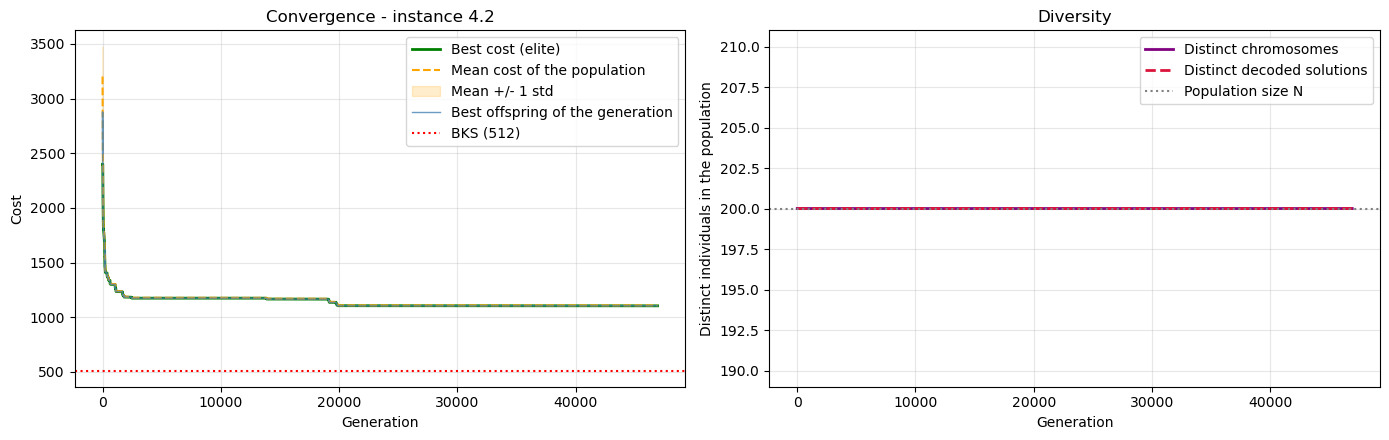

In [40]:
# ---- convergence and diversity plots -----------------------------------------------------------------------
if population is not None:
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    g_ = hist["generation"]

    ax[0].plot(g_, hist["best"], color="green", lw=2, label="Best cost (elite)")
    ax[0].plot(g_, hist["mean"], color="orange", ls="--", label="Mean cost of the population")
    ax[0].fill_between(g_, hist["mean"] - hist["std"], hist["mean"] + hist["std"], color="orange", alpha=0.2, label="Mean +/- 1 std")
    ax[0].plot(g_.iloc[1:], hist["child_best"].iloc[1:], color="steelblue", lw=1, alpha=0.8, label="Best offspring of the generation")
    ax[0].axhline(BKS[GA_LABEL], color="red", ls=":", label=f"BKS ({BKS[GA_LABEL]})")
    ax[0].set(title=f"Convergence - instance {GA_LABEL}", xlabel="Generation", ylabel="Cost")
    ax[0].legend(); ax[0].grid(alpha=0.3)

    ax[1].plot(g_, hist["distinct"], color="purple", lw=2, label="Distinct chromosomes")
    ax[1].plot(g_, hist["distinct_solutions"], color="crimson", lw=2, ls="--", label="Distinct decoded solutions")
    ax[1].axhline(len(ga_results["final_population"]), color="grey", ls=":", label="Population size N")
    ax[1].set(title="Diversity", xlabel="Generation", ylabel="Distinct individuals in the population")
    ax[1].legend(); ax[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


### Effect of the survivor rule and of the mutation rate (first tuning experiment)

Same initial population, 3 seeds, each run ends with the stopping rule or after `DEMO_TIME_S` seconds. `std` and `distinct solutions` are those of the final population.


In [41]:
if population is not None:
    rows_ = []
    for uniq in (False, True):
        for rate in (0.01, 0.03, 0.1):
            for s in range(3):
                r = run_ga(inst, population, max_time_s=DEMO_TIME_S, unique_survivors=uniq, mutation_rate=rate, seed=2000 + s, verbose=False)
                h_ = r["history"]
                collapse = h_.index[h_["distinct_solutions"] <= 3]
                rows_.append({"unique_survivors": uniq, "mutation_rate": rate, "seed": s, "best": r["best_cost"],
                              "mean_final": h_["mean"].iloc[-1], "std_final": h_["std"].iloc[-1],
                              "distinct_solutions_final": h_["distinct_solutions"].iloc[-1],
                              "collapse_gen": int(collapse[0]) if len(collapse) else None})
    cmp_df = pd.DataFrame(rows_)
    display(cmp_df.groupby(["unique_survivors", "mutation_rate"]).agg(best=("best", "mean"), mean_final=("mean_final", "mean"),
            std_final=("std_final", "mean"), distinct_final=("distinct_solutions_final", "mean"), collapse_gen=("collapse_gen", "mean")).round(2))


best  mean_final  std_final  \
unique_survivors mutation_rate                                   
False            0.01           1748.33     1748.33       0.00   
                 0.03           1925.00     1925.00       0.00   
                 0.10           2296.33     2296.33       0.00   
True             0.01           1276.33     1288.91       3.07   
                 0.03           1533.67     1537.94       1.24   
                 0.10           2085.67     2104.53       5.54   

                                distinct_final  collapse_gen  
unique_survivors mutation_rate                                
False            0.01                      1.0         64.33  
                 0.03                      1.0         49.33  
                 0.10                      1.0         33.33  
True             0.01                    200.0           NaN  
                 0.03                    200.0           NaN  
                 0.10                    200.0           NaN